In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# 1 - Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import lightgbm as lgb

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RandomizedSearchCV

 
sns.set_style("whitegrid")
pd.set_option('display.max_columns', 60)
 
RANDOM_STATE = 42
TARGET = 'TargetValue'
ID_COL = 'TransactionID'


- Imported libraries for data manipulation (Pandas, NumPy), visualization (Matplotlib, Seaborn), preprocessing (SimpleImputer, OrdinalEncoder, Pipeline, ColumnTransformer), model training (Linear Regression, Random Forest, XGBoost, LightGBM), hyperparameter tuning (RandomizedSearchCV), and evaluation.
- These libraries provide efficient, reusable implementations for building the machine learning pipeline.

# 2 - Data Loading

In [3]:
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
metadata = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')

print(f'Train shape: {train.shape}')
print(f'Test shape: {test.shape}')
print(f'\nTrain data (first 5 rows):')
print(train.head())

/tmp/ipykernel_16/1750757476.py:1: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


Train shape: (138701, 50)
Test shape: (15000, 49)

Train data (first 5 rows):
   TransactionID  TargetValue  AssetID  ProductConfigID DataOriginCode  \
0        1139309      57000.0   117665               88         ACH138   
1        1139316      26500.0  1001282             4616         ACH138   
2        1139317      21000.0   772709             1948         ACH138   
3        1139322      27000.0   902010             3550         ACH138   
4        1139333      21500.0  1036259            36014         ACH138   

  VendorPartnerID  ManufactureYear  OperationalHoursMeter UtilizationTier  \
0             GTX             1997                 4640.0             Low   
1             GTX             2005                  508.0             Low   
2             GTX             1994                11540.0            High   
3             GTX             2002                 4883.0            High   
4             GTX             2009                  302.0             Low   

  TransactionD

# 3 - Exploratory data analysis (EDA)

## 3.1 Missing value analysis


2.1 MISSING VALUES ANALYSIS
col19                    99.952416
col18                    99.952416
col5                     92.515555
col4                     92.515555
col27                    89.214930
col28                    89.214930
col29                    86.393753
col30                    86.393753
col13                    83.125572
col14                    83.125572
col7                     83.125572
col6                     83.125572
col9                     83.125572
col8                     83.125572
col11                    83.125572
col3                     78.909309
Forks                    78.861724
Spec_ReleaseSeries       76.282795
col1                     75.641127
col12                    72.340502
col15                    69.519326
DrivetrainType           64.856057
UtilizationTier          63.608770
Spec_VariantModifier     62.269919
col20                    48.799216
col25                    48.799216
col21                    48.799216
col22                    4

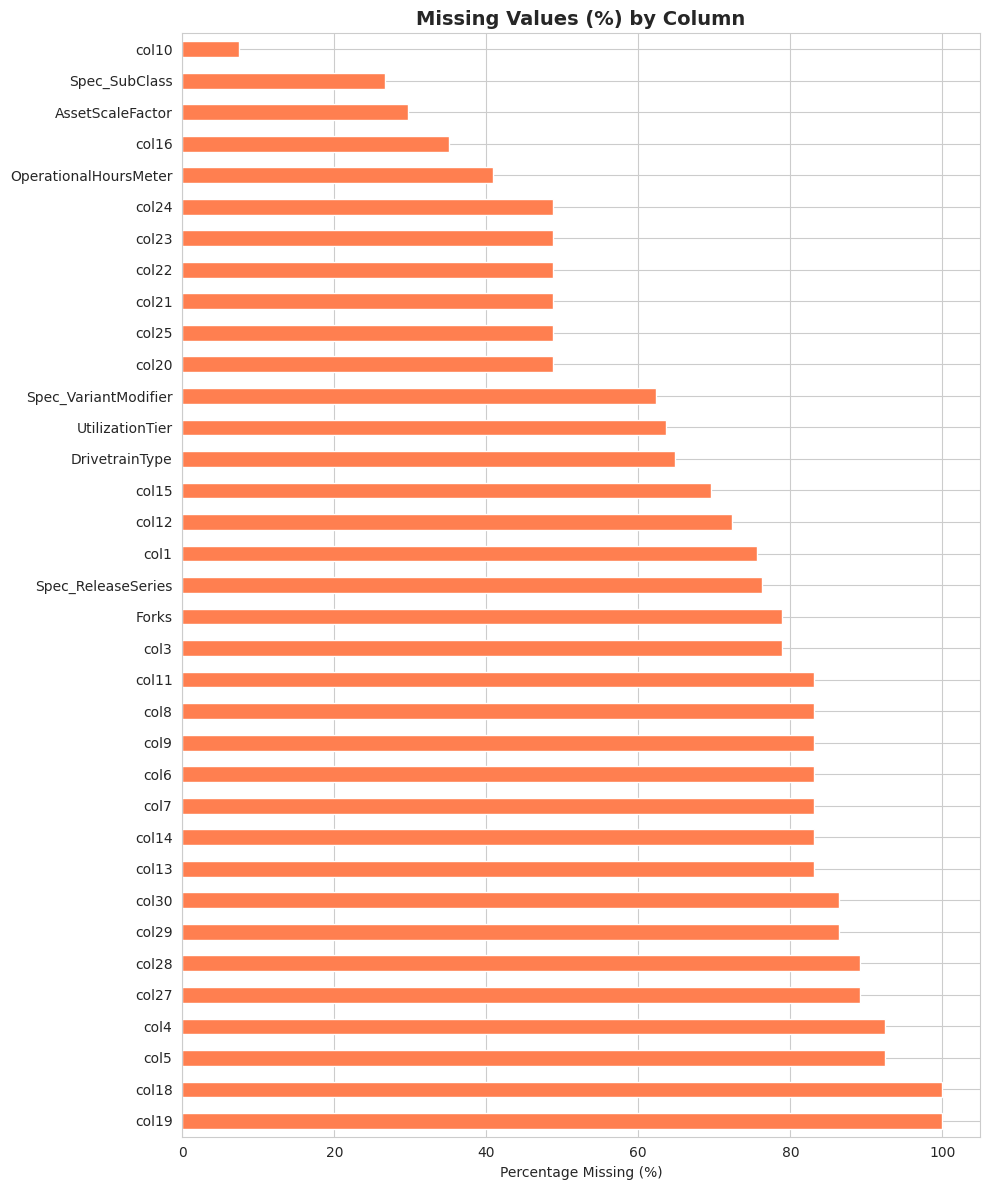

In [4]:
print("\n2.1 MISSING VALUES ANALYSIS")
missing_pct = (train.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(missing_pct)
plt.figure(figsize=(10, 12))
missing_pct.plot(kind='barh', color='coral')
plt.title('Missing Values (%) by Column', fontsize=14, fontweight='bold')
plt.xlabel('Percentage Missing (%)')
plt.tight_layout()
plt.savefig('01_missing_values.png', dpi=100, bbox_inches='tight')
plt.show()


## 3.2 Target variable distribution


2.2 TARGET VARIABLE DISTRIBUTION
Target statistics:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


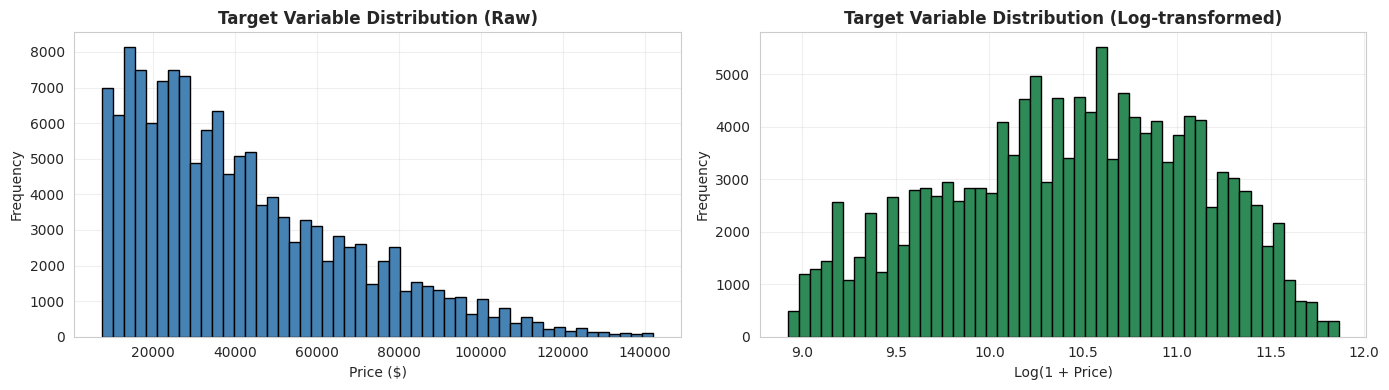


 KEY INSIGHT: Target is right-skewed → Log transformation justified for RMSLE metric


In [5]:
print("\n2.2 TARGET VARIABLE DISTRIBUTION")
print(f"Target statistics:\n{train[TARGET].describe()}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# Raw distribution
axes[0].hist(train[TARGET], bins=50, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Target Variable Distribution (Raw)', fontweight='bold')
axes[0].grid(alpha=0.3)
# Log-transformed distribution
axes[1].hist(np.log1p(train[TARGET]), bins=50, color='seagreen', edgecolor='black')
axes[1].set_xlabel('Log(1 + Price)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Target Variable Distribution (Log-transformed)', fontweight='bold')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('02_target_distribution.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n KEY INSIGHT: Target is right-skewed → Log transformation justified for RMSLE metric")

## 3.3 Price by categorical features


2.3 PRICE BY CATEGORICAL FEATURES


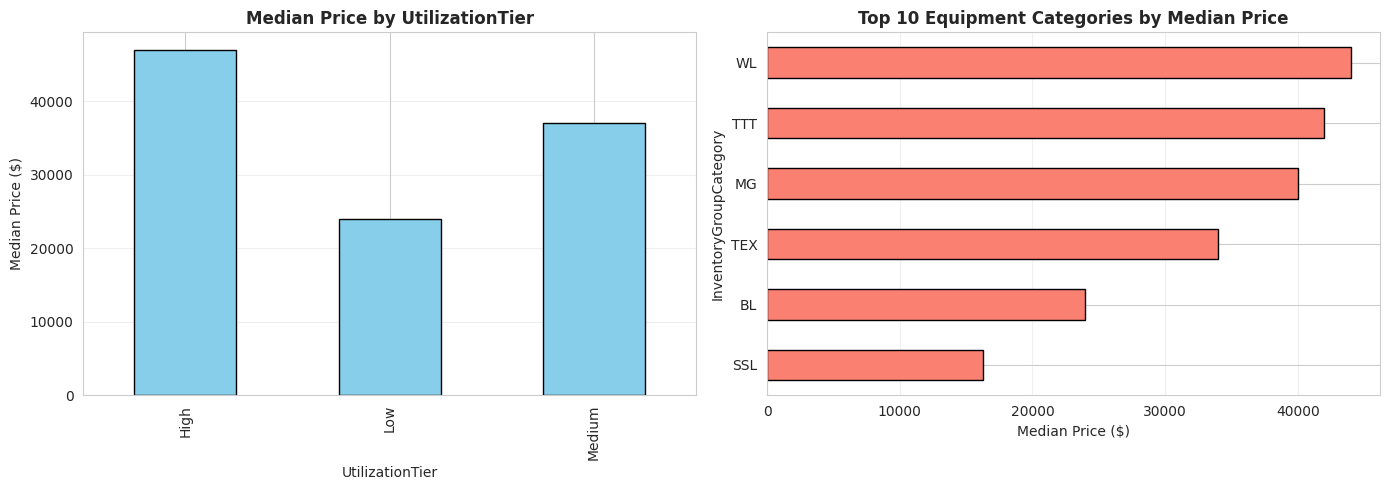

In [6]:
print("\n2.3 PRICE BY CATEGORICAL FEATURES")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
train.groupby('UtilizationTier')[TARGET].median().plot(
    kind='bar', ax=axes[0], color='skyblue', edgecolor='black'
)
axes[0].set_title('Median Price by UtilizationTier', fontweight='bold')
axes[0].set_ylabel('Median Price ($)')
axes[0].set_xlabel('UtilizationTier')
axes[0].grid(axis='y', alpha=0.3)
top_categories = train.groupby('InventoryGroupCategory')[TARGET].median().sort_values(ascending=True).tail(10)
top_categories.plot(kind='barh', ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title('Top 10 Equipment Categories by Median Price', fontweight='bold')
axes[1].set_xlabel('Median Price ($)')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('03_price_by_categories.png', dpi=100, bbox_inches='tight')
plt.show()

## 3.4 Spec_FullDescriptor sample inspection

In [7]:
print("\n2.4 SPEC_FULLDESCRIPTOR ANALYSIS")
print("Sample values from Spec_FullDescriptor:")
print(train['Spec_FullDescriptor'].dropna().sample(10, random_state=1).to_string())
print(f"Missing values: {train['Spec_FullDescriptor'].isna().sum()} / {len(train)}")
print("\n OBSERVATION: Pattern like '345BIIL', 'PC75UU-2', 'D6HIIXL' suggests")
print("   embedded numeric model-size codes. Extracting these will capture")
print("   SIZE information not available in separate Spec_BaseClass/SubClass columns.")


2.4 SPEC_FULLDESCRIPTOR ANALYSIS
Sample values from Spec_FullDescriptor:
91069        345BIIL
97272           490E
66103       PC75UU-2
104503    ROBEX210LC
86612           966B
74109           322G
53155           544H
3182           TB016
28468            12G
92886           312C
Missing values: 0 / 138701

 OBSERVATION: Pattern like '345BIIL', 'PC75UU-2', 'D6HIIXL' suggests
   embedded numeric model-size codes. Extracting these will capture
   SIZE information not available in separate Spec_BaseClass/SubClass columns.


# 4 - Feature Engineering

In [8]:
def engineer(df):
  
    df = df.copy()  # FIX: Always copy to avoid modifying original
    
    # Convert to datetime
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])
    df['TransactionYear'] = df['TransactionDate'].dt.year
    df['TransactionMonth'] = df['TransactionDate'].dt.month
    
    # Handle ManufactureYear placeholder (1001 = unknown)
    df['ManufactureYear_unknown'] = (df['ManufactureYear'] == 1001).astype(int)
    df['ManufactureYear'] = df['ManufactureYear'].replace(1001, np.nan)
    
    # Calculate equipment age
    df['EquipmentAge'] = df['TransactionYear'] - df['ManufactureYear']
    df.loc[df['EquipmentAge'] < 0, 'EquipmentAge'] = np.nan  # Fix data-entry errors
    
    # Extract model size from Spec_FullDescriptor
    extracted = df['Spec_FullDescriptor'].str.extract(r'(\d+)')
    df['SpecFD_ModelNumber'] = pd.to_numeric(extracted[0], errors='coerce')
    df['SpecFD_StringLength'] = df['Spec_FullDescriptor'].str.len()
    
    # Drop columns no longer needed
    df = df.drop(columns=['TransactionDate', 'AssetID'])
    
    return df
 



 
train_fe = engineer(train)
test_fe = engineer(test)
 
print(f'\n Feature engineering complete')
print(f'Train shape after FE: {train_fe.shape}')
print(f'Test shape after FE: {test_fe.shape}')


 Feature engineering complete
Train shape after FE: (138701, 54)
Test shape after FE: (15000, 53)


EquipmentAge - It is better than manufacture year because equipment age affects selling price. 
Spec_FullDescriptor - Extracted numbers to use hidden information(like model_size, series) from the descriptor.

# 5 - Prepare train and validation split

In [9]:
y = train_fe[TARGET].copy()
X = train_fe.drop(columns=[TARGET, ID_COL])
test_ids = test_fe[ID_COL].copy()
X_test = test_fe.drop(columns=[ID_COL])

# Temporal split: respects time-series nature of price data
print("\n Using TEMPORAL SPLIT (not random) because prices drift over time")
print("   Split: 80% train, 20% validation (most recent data)")

sort_idx = train_fe.sort_values(['TransactionYear', 'TransactionMonth']).index
split_point = int(len(sort_idx) * 0.8)
tr_idx, val_idx = sort_idx[:split_point], sort_idx[split_point:]

X_tr, X_val = X.loc[tr_idx], X.loc[val_idx]
y_tr, y_val = y.loc[tr_idx], y.loc[val_idx]

print(f"Train set: {X_tr.shape[0]} samples")
print(f"Val set: {X_val.shape[0]} samples")
print(f"Train date range: {train_fe.loc[tr_idx, 'TransactionYear'].min():.0f} - {train_fe.loc[tr_idx, 'TransactionYear'].max():.0f}")
print(f"Val date range: {train_fe.loc[val_idx, 'TransactionYear'].min():.0f} - {train_fe.loc[val_idx, 'TransactionYear'].max():.0f}")


 Using TEMPORAL SPLIT (not random) because prices drift over time
   Split: 80% train, 20% validation (most recent data)
Train set: 110960 samples
Val set: 27741 samples
Train date range: 1990 - 2011
Val date range: 2011 - 2013


- Applied log1p to the target after splitting to align training with the RMSLE evaluation metric while keeping the validation workflow independent.

 # 6 - Data Preprocessing (Pipeline and ColumnTransformer)

In [10]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"\nNumeric columns ({len(num_cols)}): {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")




Numeric columns (9): ['ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter', 'TransactionYear', 'TransactionMonth', 'ManufactureYear_unknown', 'EquipmentAge', 'SpecFD_ModelNumber', 'SpecFD_StringLength']
Categorical columns (43): ['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


## 6.1 Build Preprocessing Pipeline

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ]
)

## 6.2 Apply the Preprocessing Pipeline

In [12]:
X_tr_final = preprocessor.fit_transform(X_tr)
X_val_final = preprocessor.transform(X_val)
X_test_final = preprocessor.transform(X_test)

feat_names = num_cols + cat_cols

print(f"Preprocessing complete. Final feature matrix shape: {X_tr_final.shape}")

Preprocessing complete. Final feature matrix shape: (110960, 52)


# 7 - Model training and evaluation

In [13]:
def rmsle_from_log_pred(y_true, log_pred):
    """Calculate RMSLE from log-space predictions."""
    pred = np.clip(np.expm1(log_pred), 0, None)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(pred)))

y_tr_log = np.log1p(y_tr)  # Transform target to log space


## 7.1 Linear Regression

In [14]:
print("\n6.1 LINEAR REGRESSION")
lin_reg = LinearRegression()
lin_reg.fit(X_tr_final, y_tr_log)
lin_rmsle = rmsle_from_log_pred(y_val, lin_reg.predict(X_val_final))
print(f"   Val RMSLE: {lin_rmsle:.4f}")


6.1 LINEAR REGRESSION
   Val RMSLE: 0.4995


## 7.2 Random Forest

In [15]:
print("\n7.2 RANDOM FOREST (200 trees, max_depth=None)")
rf_reg = RandomForestRegressor(
    n_estimators=200, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE
)
rf_reg.fit(X_tr_final, y_tr_log)
rf_rmsle = rmsle_from_log_pred(y_val, rf_reg.predict(X_val_final))
print(f"   Val RMSLE: {rf_rmsle:.4f}")


7.2 RANDOM FOREST (200 trees, max_depth=None)
   Val RMSLE: 0.2911


### 7.2.1 Hyperparameter tunning (random forest)

In [16]:
print("\n7.3 HYPERPARAMETER TUNING - RANDOM FOREST")

param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_distributions=param_dist,
    n_iter=3,
    cv=2,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_search.fit(X_tr_final, y_tr_log)

best_rf = rf_search.best_estimator_

rf_tuned_pred = best_rf.predict(X_val_final)

rf_tuned_rmsle = rmsle_from_log_pred(
    y_val,
    rf_tuned_pred
)

print("\nBest Hyperparameters:")
print(rf_search.best_params_)

print(f"\nTuned Random Forest RMSLE: {rf_tuned_rmsle:.4f}")


7.3 HYPERPARAMETER TUNING - RANDOM FOREST

Best Hyperparameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}

Tuned Random Forest RMSLE: 0.2899


A RandomizedSearchCV was performed to tune the Random Forest model by testing multiple hyperparameter combinations.

The tuned model was evaluated on the validation set and compared with the baseline Random Forest.

Although hyperparameter tuning improved the Random Forest model, the XGBoost–LightGBM ensemble achieved the lowest validation RMSLE and was selected as the final model.

## 7.3 XGBoost

In [17]:
print("\n7.3 XGBOOST (max_depth=9, early stopping)")
xgb_final = XGBRegressor(
    n_estimators=3000, max_depth=9, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_STATE,
    early_stopping_rounds=50, eval_metric='rmse'
)
xgb_final.fit(
    X_tr_final, y_tr_log, 
    eval_set=[(X_val_final, np.log1p(y_val))], 
    verbose=False
)
xgb_val_pred = xgb_final.predict(X_val_final)
xgb_rmsle = rmsle_from_log_pred(y_val, xgb_val_pred)
print(f"   Stopped at iteration: {xgb_final.best_iteration}")
print(f"   Val RMSLE: {xgb_rmsle:.4f}")


7.3 XGBOOST (max_depth=9, early stopping)
   Stopped at iteration: 1153
   Val RMSLE: 0.2655


## 7.4 LightGBM

In [18]:
print("\n7.4 LIGHTGBM (num_leaves=255, early stopping)")
lgbm_final = LGBMRegressor(
    n_estimators=3000, num_leaves=255, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1
)
lgbm_final.fit(
    X_tr_final, y_tr_log,
    eval_set=[(X_val_final, np.log1p(y_val))],
    callbacks=[lgb.early_stopping(50, verbose=False)]
)
lgbm_val_pred = lgbm_final.predict(X_val_final)
lgbm_rmsle = rmsle_from_log_pred(y_val, lgbm_val_pred)
print(f"Stopped at iteration: {lgbm_final.best_iteration_}")
print(f"   Val RMSLE: {lgbm_rmsle:.4f}")


7.4 LIGHTGBM (num_leaves=255, early stopping)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Stopped at iteration: 884
   Val RMSLE: 0.2639


# 8 - Model comparison

In [19]:
ENSEMBLE_WEIGHT_XGB = 0.5
ensemble_val_pred = (
    ENSEMBLE_WEIGHT_XGB * xgb_val_pred
    + (1 - ENSEMBLE_WEIGHT_XGB) * lgbm_val_pred
)
ensemble_rmsle = rmsle_from_log_pred(y_val, ensemble_val_pred)

results = {
    'LinearRegression': lin_rmsle,
    'RandomForest': rf_rmsle,
    'RandomForest (Tuned)': rf_tuned_rmsle,
    'XGBoost': xgb_rmsle,
    'LightGBM': lgbm_rmsle,
    'Ensemble (50/50)': ensemble_rmsle
}

for name, score in sorted(results.items(), key=lambda x: x[1]):
    print(f"{name:25s}: {score:.4f}")

best_model_name = min(results, key=results.get)
print(f"\nBEST MODEL: {best_model_name} ({results[best_model_name]:.4f})")

Ensemble (50/50)         : 0.2632
LightGBM                 : 0.2639
XGBoost                  : 0.2655
RandomForest (Tuned)     : 0.2899
RandomForest             : 0.2911
LinearRegression         : 0.4995

BEST MODEL: Ensemble (50/50) (0.2632)



 -Used Linear Regression as a baseline.
- Used Random Forest, XGBoost, and LightGBM to capture non-linear relationships.
- Tuned Random Forest using RandomizedSearchCV.
- Selected the best-performing model based on validation RMSLE and used an XGBoost + LightGBM ensemble for the final predictions.

## 8.1 Plot model comparison

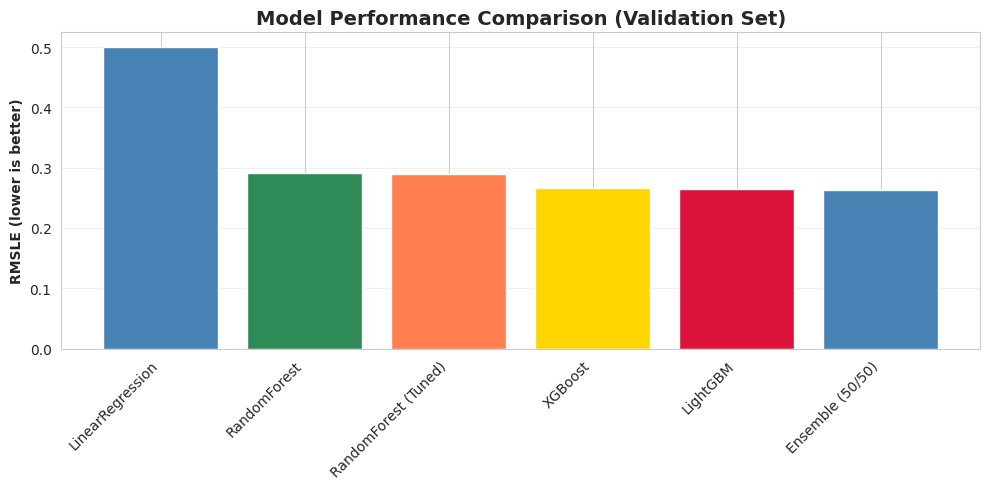

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
model_names = list(results.keys())
model_scores = list(results.values())
bars = ax.bar(model_names, model_scores, color=['steelblue', 'seagreen', 'coral', 'gold', 'crimson'])
ax.set_ylabel('RMSLE (lower is better)', fontweight='bold')
ax.set_title('Model Performance Comparison (Validation Set)', fontweight='bold', fontsize=14)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('04_model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

# 9 - Feature importance and analysis

## 9.1 - XGBoost feature importance


Top 15 XGBoost Features:
                      Feature  Importance
17           AssetScaleFactor    0.186740
29                       col6    0.163154
42                      col20    0.150993
20     InventoryGroupCategory    0.104727
21  InventoryGroupDescription    0.055537
31                       col8    0.033947
6                EquipmentAge    0.029945
18   FunctionalClassification    0.023395
23                  CabinType    0.023029
13             Spec_BaseClass    0.018263
16       Spec_VariantModifier    0.012186
5     ManufactureYear_unknown    0.011779
41                      col19    0.011778
38                      col15    0.011624
12        Spec_FullDescriptor    0.010828


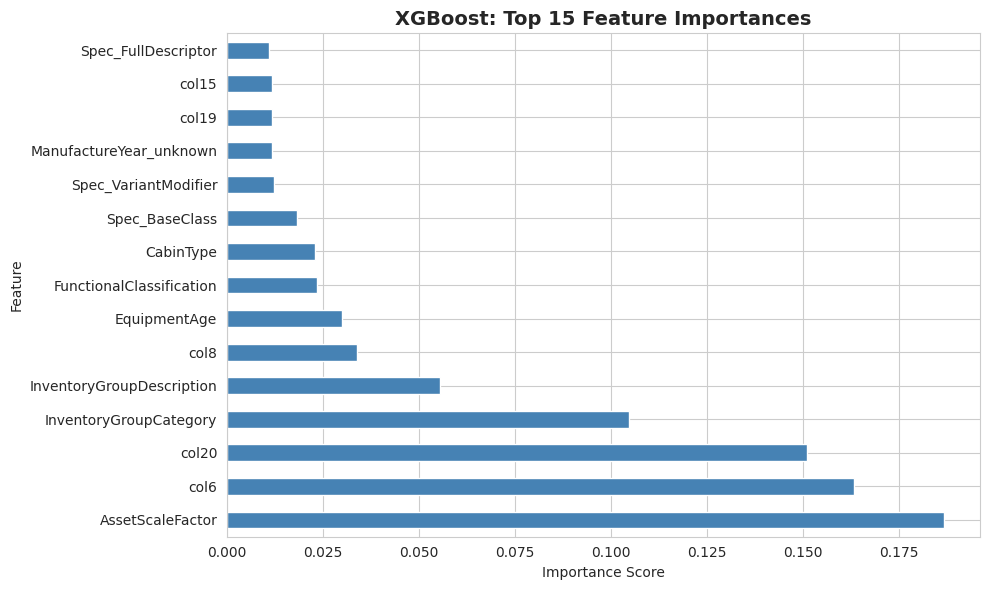

In [21]:
xgb_importance = pd.DataFrame({
    'Feature': feat_names,
    'Importance': xgb_final.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 XGBoost Features:")
print(xgb_importance.head(15))

fig, ax = plt.subplots(figsize=(10, 6))
xgb_importance.head(15).plot(kind='barh', x='Feature', y='Importance', ax=ax, legend=False, color='steelblue')
ax.set_title('XGBoost: Top 15 Feature Importances', fontweight='bold', fontsize=14)
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.savefig('05_xgb_feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

## 9.2 - LightGBM feature importance

In [22]:
lgbm_importance = pd.DataFrame({
    'Feature': feat_names,
    'Importance': lgbm_final.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 LightGBM Features:")
print(lgbm_importance.head(15))


Top 15 LightGBM Features:
                     Feature  Importance
19                RegionCode       19744
0            ProductConfigID       17649
7         SpecFD_ModelNumber       16723
12       Spec_FullDescriptor       16103
3            TransactionYear       15937
1            ManufactureYear       14985
4           TransactionMonth       14092
6               EquipmentAge       13901
18  FunctionalClassification       11071
2      OperationalHoursMeter       10296
10           VendorPartnerID        9877
14             Spec_SubClass        9295
13            Spec_BaseClass        6477
8        SpecFD_StringLength        4549
16      Spec_VariantModifier        4406


# 10 - Final prediction on test set
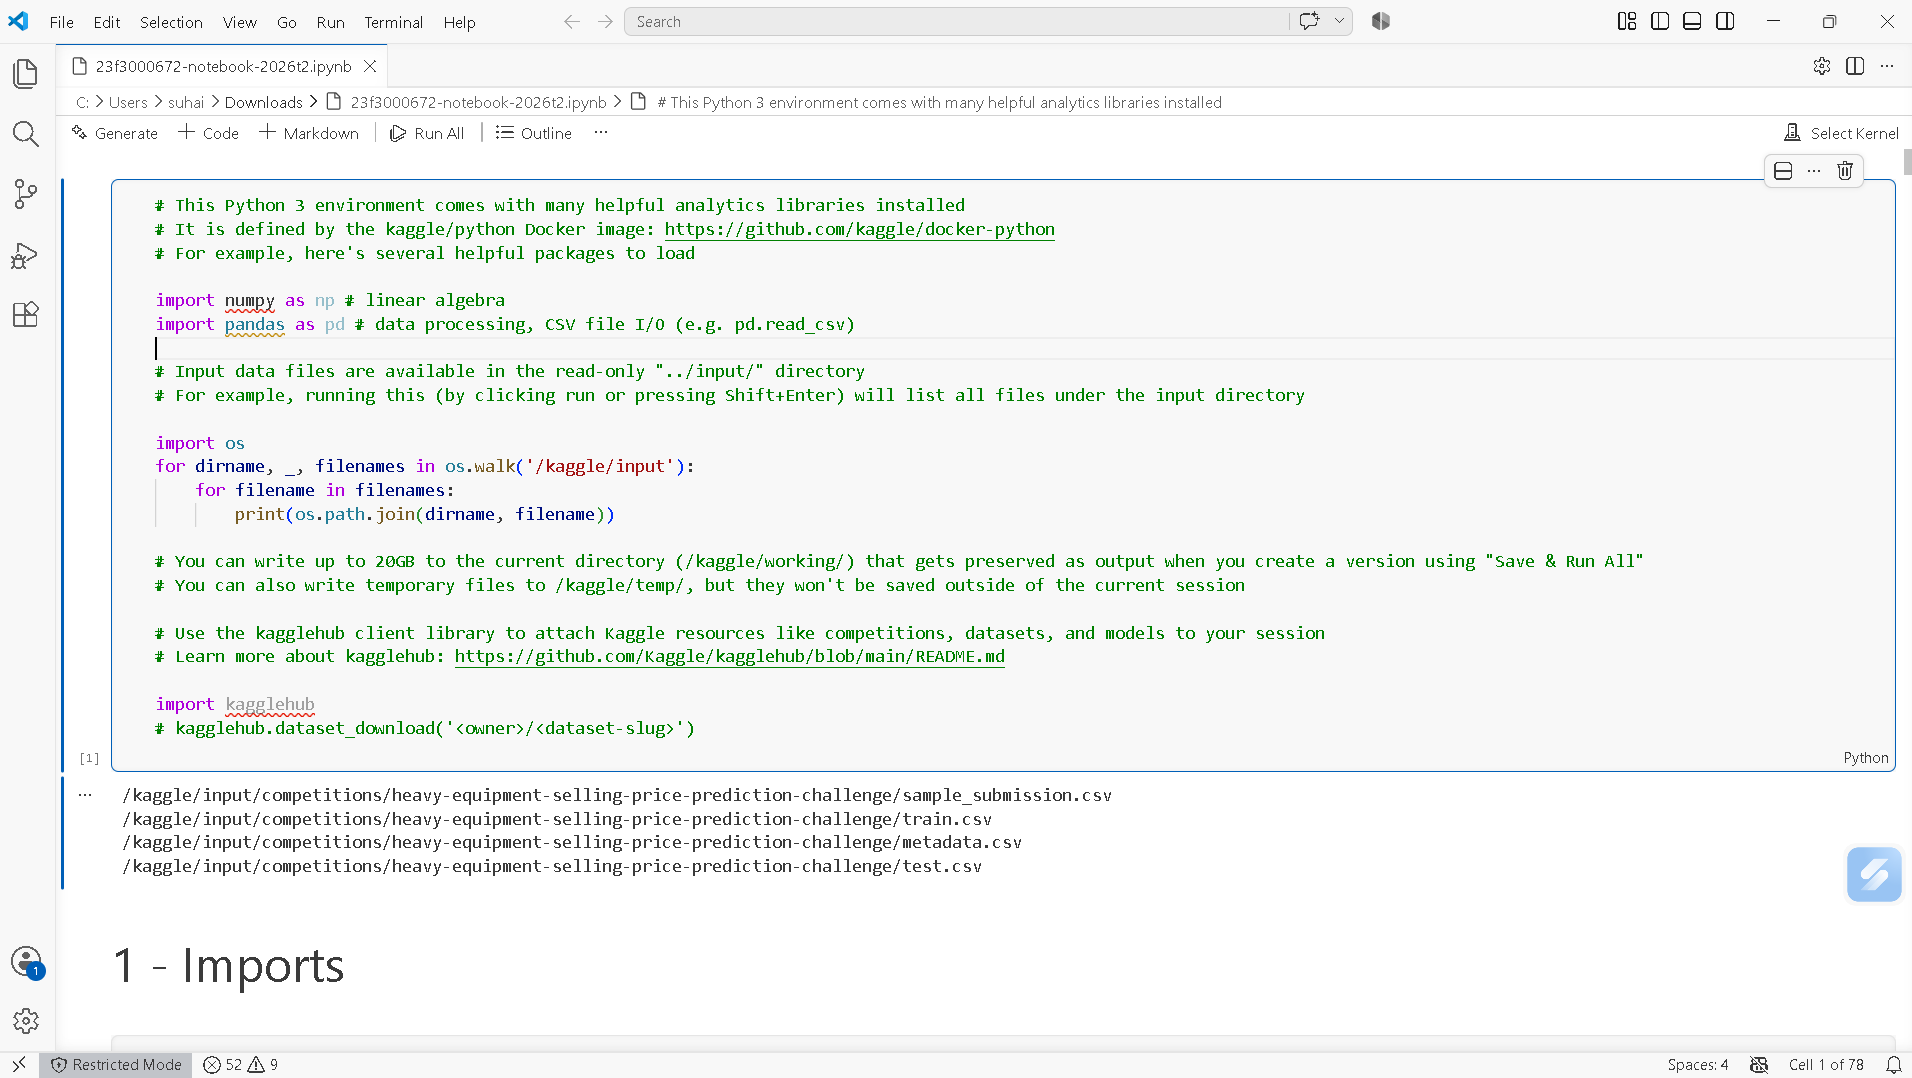

## 10.1 - Refit on full training data with scaled iterations

In [23]:
# Apply the same preprocessing pipeline to the full training and test data
X_full_final = preprocessor.fit_transform(X)
X_test_final_full = preprocessor.transform(X_test)

y_log_full = np.log1p(y)

XGB_BEST_ITERATION = xgb_final.best_iteration
LGBM_BEST_ITERATION = lgbm_final.best_iteration_

## 10.2 - Refit XGBoost

In [24]:
final_xgb_n_estimators = int(XGB_BEST_ITERATION * 1.25)
xgb_full = XGBRegressor(
    n_estimators=final_xgb_n_estimators, max_depth=10, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_STATE
)
xgb_full.fit(X_full_final, y_log_full)
xgb_test_pred = xgb_full.predict(X_test_final_full)
print(f"Refit XGBoost on full data (n_estimators={final_xgb_n_estimators})")


Refit XGBoost on full data (n_estimators=1441)


## 10.3 - Refit LightGBM

In [25]:
final_lgbm_n_estimators = int(LGBM_BEST_ITERATION * 1.25)
lgbm_full = LGBMRegressor(
    n_estimators=final_lgbm_n_estimators, num_leaves=255, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1
)
lgbm_full.fit(X_full_final, y_log_full)
lgbm_test_pred = lgbm_full.predict(X_test_final_full)
print(f"Refit LightGBM on full data (n_estimators={final_lgbm_n_estimators})")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Refit LightGBM on full data (n_estimators=1105)


## 10.4 - Ensemble prediction

In [26]:
ensemble_test_pred_log = ENSEMBLE_WEIGHT_XGB * xgb_test_pred + (1 - ENSEMBLE_WEIGHT_XGB) * lgbm_test_pred
test_pred = np.clip(np.expm1(ensemble_test_pred_log), 0, None)

# 11 - Submission and Validation

In [27]:
submission = pd.DataFrame({ID_COL: test_ids, TARGET: test_pred})
submission.to_csv('submission.csv', index=False)

print(f"\n Submission preview:")
print(submission.head(10))
print(f"\n Submission statistics:")
print(f"   Total predictions: {len(submission)}")
print(f"   Price range: ${submission[TARGET].min():.0f} - ${submission[TARGET].max():.0f}")
print(f"   Mean price: ${submission[TARGET].mean():.0f}")
print(f"   Median price: ${submission[TARGET].median():.0f}")


 Submission preview:
   TransactionID   TargetValue
0        1139307  68822.991493
1        1139419  80197.662169
2        1139482  32498.866873
3        1139522  20972.886682
4        1139684  12664.085273
5        1139773  30069.521280
6        1139779  20586.175028
7        1139793  45285.628597
8        1139814  75647.997774
9        1139839  15719.282820

 Submission statistics:
   Total predictions: 15000
   Price range: $7647 - $136793
   Mean price: $40815
   Median price: $34587


`expm1`- - Converted predictions back to the original price scale using 

#  Milestones 

## Milestone-1

In [28]:
# # 1- How many records (rows) are present in the train.csv and test.csv datasets, respectively?

# train = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv")
# test  = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
# print(f" Rows in training set is {train.shape[0]}")
# print(f" Rows in test set is {test.shape[0]}")

In [29]:
# # # 2- By doing a strict set difference between the columns in train.csv and test.csv, which column is correctly identified as the sole target variable we need to predict?
# print(train.columns)
# print(test.columns)
# #set difference 
# print(set(train.columns) - set(test.columns)) # Return all column names that are present in the training dataset but absent from the test dataset
# # #set(test.columns) - set(train.columns) # set(), Empty set,because there is nothing in test data which is not in train.



In [30]:
# # 3- In the training dataset, how many columns are strictly recognized as numerical features (int64 or float64) by default?
# print(train.info())

# result = train.select_dtypes(include= ['int64','float64'])

# print(result.shape[1])


In [31]:
# 4- Which of the following configuration columns exhibit a missing value rate higher than 90% 
#(missing over 124,800 rows out of 138,701) in the training set and should likely be dropped or heavily grouped?

# missing = train.isnull().sum()

# missing[missing > 0.9 * train.shape[0]]


In [32]:
# 5- The OperationalHoursMeter represents the lifetime active runtime of the machine.
# What is the approximate percentage of missing values for this critical column in the training dataset?

# op_missing = missing['OperationalHoursMeter']

# percentage = op_missing/train.shape[0]*100

# print(percentage)


In [33]:
# 6- Heavy machinery prices are often right-skewed.
# What is the median of TargetValue (transaction price) in the dataset?

# mean_price = train['TargetValue'].mean()
# median_price = train['TargetValue'].median()

# print(mean_price)
# print(median_price)

#Mean > Median (There are some unusually large values pulling the average upward)
#That is exactly what a right-skewed (positively skewed)



In [34]:
# Question 7 (Numeric): Manufacture Year Anomaly
# When analyzing the ManufactureYear, you will find a strange anomaly.
# What is the most frequently occurring (mode) ManufactureYear in the dataset, indicating a default placeholder value used by the data entry system?

# train['ManufactureYear'].mode()
#train['ManufactureYear'].value_counts().head(10)
#(train['ManufactureYear'] == 1001).sum()


In [35]:
# Question 8 (MCQ): Time Span of Transactions
# What is the earliest (minimum) TransactionDate recorded in the training dataset?

# train['TransactionDate'].min()

# train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
# train['TransactionDate'].dtype



In [36]:
# Question 9 (Numeric): High Cardinality Identification
# Machine learning models struggle with high-cardinality categorical features.
# How many unique string classes exist within the Spec_BaseClass column?

# #train['Spec_BaseClass'].unique()
# train['Spec_BaseClass'].nunique()



## Milestone-2

In [37]:
# # Section 1: Feature Engineering

# # Create the following new features on the training dataset:

# ## TransactionYear – Extracted from TransactionDate
# train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])

# train['TransactionYear'] = train['TransactionDate'].dt.year

# #train['TransactionYear','TransactionDate']
# ## TransactionQuarter – Extracted from TransactionDate
# train['TransactionQuarter'] = train['TransactionDate'].dt.quarter
# #train[['TransactionQuarter','TransactionDate']]

# ## AssetAge – TransactionYear - ManufactureYear
# train['AssetAge'] = train['TransactionYear'] - train['ManufactureYear']

# ## DescriptorLength – Number of characters in Spec_FullDescriptor
# train['DescriptorLength'] = train['Spec_FullDescriptor'].str.len()
# ## HasOperationalHours – Assign 1 if OperationalHoursMeter is available, otherwise 0
# train['HasOperationalHours'] = train['OperationalHoursMeter'].notnull().astype(int)

# #train[['HasOperationalHours', 'OperationalHoursMeter']]

# ## HasVariantModifier – Assign 1 if Spec_VariantModifier is available, otherwise 0
# train['HasVariantModifier'] = train['Spec_VariantModifier'].notnull().astype(int)


In [38]:
# # 1- Which AssetAge occurs most frequently in the training dataset?

# train['AssetAge'].mode()

In [39]:
# # 2- Which TransactionQuarter has the highest average TargetValue?
# train['TransactionQuarter'].mean().max()

# train[['TransactionQuarter', 'TargetValue']]

## Milestone-3

## Milestone-4

## Milestone-5